# Beyond the port

Most of Spynach is a port, checked stage by stage against Spinach. This guide
collects the add-ons originating here: features with no Spinach counterpart,
and modules that live beside the port. Each entry has a
short example and points to the guide that covers it in depth. The companion
notebook is [`notebooks/beyond-the-port.ipynb`](beyond-the-port.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/beyond-the-port.ipynb)).

*Generated from [`docs/beyond-the-port.md`](../beyond-the-port.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Coherence transfer pathway selection: `ctps`](#Coherence-transfer-pathway-selection:-ctps)
2. [Non-ideal pulses and cogwheel cycle search](#Non-ideal-pulses-and-cogwheel-cycle-search)
10. [Pulse programs, gradients, phase cycling (beta)](#Pulse-programs,-gradients,-phase-cycling-(beta))
3. [Interactive figures and static copies](#Interactive-figures-and-static-copies)
4. [Checking results: `compare`, the parity page, timed reports](#Checking-results:-compare,-the-parity-page,-timed-reports)
5. [Executable documentation, Colab, contributed notebooks](#Executable-documentation,-Colab,-contributed-notebooks)
6. [Spynach in the browser](#Spynach-in-the-browser)
7. [EPR with EasySpyn](#EPR-with-EasySpyn)
8. [Relaxation pathways by mechanism](#Relaxation-pathways-by-mechanism)
9. [Radiation damping](#Radiation-damping)

## Coherence transfer pathway selection: `ctps`

Spinach simulates the spin dynamics of a sequence; it does not enumerate the
coherence transfer pathways a phase cycle or gradient scheme lets through.
`ctps`, a separate module in this repository (`import ctps`, no dependency on
`spynach`), ports the CCCP.m and CCCP++ programs (Jerschow & Müller, *J. Magn.
Reson.* 134, 17 (1998); Jerschow & Kumar, *J. Magn. Reson.* 160, 59 (2003)):
every pathway the allowed orders permit, weighted by the phase cycle, the
gradients, diffusion and the pulses, ranked, and drawn. A spin echo whose
180° pulse is 0.2 rad short, with a two-step cycle on that pulse and a crusher
pair around it: the cycle alone would let the non-inverted pathway through,
the crushers dephase it, and the pulse error sets how much of it exists:

In [1]:
import numpy as np

from ctps import AllowedOrders, Nucleus, Period, PhaseCycle, Pulse, Sequence, simulate

ms = 1e-3
echo = Sequence(
    nuclei=(Nucleus("1H"),),
    pulses=(Pulse("1H", label="90"), Pulse("1H", "imperfect_180", beta=0.2, label="180")),
    periods=(Period(), Period.with_gradient(5 * ms, "z", 0.1, 1 * ms), Period.with_gradient(5 * ms, "z", 0.1, 1 * ms)),
    allowed={"1H": AllowedOrders.standard(1, 3)},
    diffusion=2e-9,
)
cycle = PhaseCycle.explicit(phases=[[0], [0, 2]], receiver=[0, 0], base=4)
result = simulate(echo, cycle, wanted=[(0, 1, -1)], cutoff=0)
for row in result.table():
    print(
        row["pathway"],
        f"pc {row['pc']:.2f}  grad {row['grad']:.4f}  diff {row['diff']:.3f}  pulse {row['pulse']:.3f}  total {row['total']:.2e}",
    )

[0, 1, -1] pc 1.00  grad 1.0000  diff 0.993  pulse 1.000  total 9.93e-01
[0, -1, -1] pc 1.00  grad 0.0037  diff 0.965  pulse 0.010  total 3.61e-05


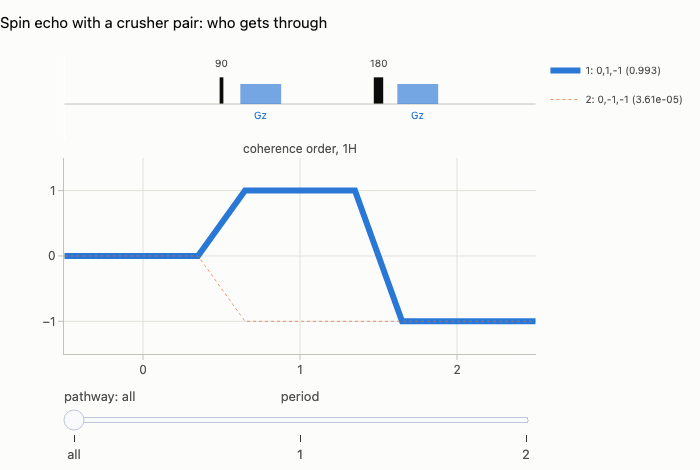

In [2]:
from ctps.plot import plot_pathways

plot_pathways(result, top=5, title="Spin echo with a crusher pair: who gets through")

The explorer draws the sequence above the coherence orders, scales every
pathway's line width by its weight, and steps through the pathways with a
slider, listing the phase-cycle, gradient, diffusion and pulse factors of each.
[Coherence transfer pathways](ctps.ipynb) is the full guide; `src/ctps/README.md`
says how to remove the module without touching Spynach.

## Non-ideal pulses and cogwheel cycle search

Two parts of `ctps` are new even relative to the programs it ports. Each pulse
can be declared a perfect 180°, an imperfect 180° (deviation `beta`, axis tilt
`epsilon`) or a small-flip-angle pulse, and the leakage of every coherence
transfer follows Jerschow, *J. Chem. Phys.* 113, 979 (2000), whose formulas and
tables were recomputed before use. And `find_cycle` searches cogwheel phase
cycles by exact integer arithmetic, testing all winding numbers at once as one
integer matrix product, with the symmetry reductions of the literature, while
`coverage` finds the best cycle for a fixed number of steps and
`crusher_scheme` optimises gradient areas with the DOTCOPS objective:

In [3]:
from ctps import coverage, find_cycle, hcl_cycle

mqmas = Sequence.simple(n_pulses=3, p_max=3)
print("Hughes-Carravetta-Levitt construction:", hcl_cycle([3, 1], [3, 3]).cog_string())
print("smallest cycle found:", find_cycle(mqmas, [(0, 3, 1, -1)]).best.cog_string())
print("best 8-step cycle for sLASER:", coverage(Sequence.simple(5, 1), [(0, -1, 1, -1, 1, -1)], 8).best.cog_string())

Hughes-Carravetta-Levitt construction: COG23(0,3,4;14)
smallest cycle found: COG23(0,1,9;20)
best 8-step cycle for sLASER: COG8(0,1,0,1,0;4)


## Interactive figures and static copies

Spinach draws into MATLAB figures. Spynach's `plot_1d` and `plot_2d` follow
Spinach's parameters but return interactive Plotly figures; `plot_fid`,
`plot_time_series` and `plot_trajan` have no Spinach counterpart, and
`figure_png` turns any of them into a PNG (through Kaleido when it can run,
otherwise a Matplotlib redraw) for GitHub, reports and papers. The notebooks in
this repository are saved with both the interactive figure and its PNG copy,
which is what GitHub's viewer shows.

In [4]:
import spynach

spin_system = spynach.create(
    {"isotopes": ["1H", "1H"], "magnet": 14.1},
    {"zeeman": {"scalar": [1.0, 1.1]}, "coupling": {"scalar": [[0, 12.0], [0, 0]]}},
)
spin_system = spynach.basis(spin_system, {"formalism": "zeeman-hilb", "approximation": "none"})
parameters = {
    "spins": ["1H"],
    "offset": 630,
    "sweep": 200,
    "npoints": 512,
    "rho0": spynach.state(spin_system, "L+", "1H"),
    "coil": spynach.state(spin_system, "L+", "1H"),
}
fid = spynach.apodisation(spynach.liquid(spin_system, spynach.acquire, parameters, "nmr"), [("exp", 6)])

54 KB of PNG


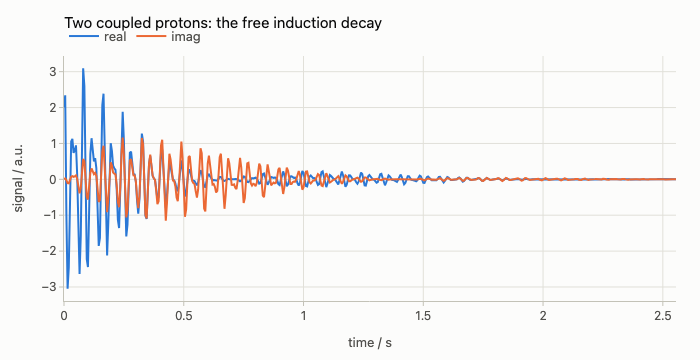

In [5]:
from spynach.plotting import figure_png, plot_fid

fig = plot_fid(fid, parameters, title="Two coupled protons: the free induction decay")
print(f"{len(figure_png(fig, scale=1)) / 1024:.0f} KB of PNG")
fig

## Checking results: `compare`, the parity page, timed reports

Spinach has no reference implementation to compare against; Spynach has
Spinach. `spynach.oracle.compare` is the normwise comparison behind the parity
suite and works on any pair of arrays, so a Spinach `.mat` result can be checked
against a Spynach run (see [Checking your own workflow against Spinach](coming-from-spinach.ipynb#Checking-your-own-workflow-against-Spinach)).
[Parity with Spinach](../parity.md), regenerated from the test suite, lists every
fixture case, tolerance and measured difference, and
[`comparison/README.md`](../../comparison/README.md) is the protocol for timed and
profiled Spinach-vs-Spynach runs with an HTML report.

In [6]:
from spynach.oracle import compare

reference = fid * (1 + 1e-11)  # stands in for the same FID computed by Spinach
print(compare(fid, reference, rtol=1e-9, atol=0, name="fid"))

PASS fid (512,): rel_err=1.000e-11 max_abs_err=3.146e-11 ref_norm=1.318e+01 (rtol=1e-09, atol=0)


## Executable documentation, Colab, contributed notebooks

Every guide in `docs/` is Markdown whose Python blocks run in the test suite,
with a notebook generated from it and saved with outputs
(`docs/build_notebooks.py`). `docs/colab/quick-start.ipynb` installs Spynach
in Google Colab and runs the quick-start example in the browser. `user_py/`
holds contributed notebooks, such as the triple-quantum build-up of a 23Na
spin under quadrupolar relaxation, beside the contributed Spinach scripts in
`user_ml/` and their translations in `examples/user_ml/`.

## Spynach in the browser

[`try.html`](https://ajerschow.github.io/spynach/try.html) on the project site
runs Spynach, `easyspyn` and `ctps` with nothing installed. The page loads
[Pyodide](https://pyodide.org/) (Python compiled to WebAssembly) with NumPy,
SciPy and h5py in a web worker, fetches the sources from the repository, and
runs the code in its editor; the first load takes a few seconds. The examples
are grouped by package, NMR, EPR, pathways and relaxation, and a link such as
`try.html#ex-epr-hyscore` opens and runs one of them. Results are drawn with
`show_spectrum(y, x)`, `show_fid(fid, sweep)`, `show_image(z, x, y)` (2D
contours, high ppm at the left and bottom as in `plot_2d`) and
`show_pathways(pathways)` (the chord diagram of `relaxation_pathways`, see
below; SymPy is loaded the first time it is needed); an `easyspyn`
`Spectrum` can be passed as it is, and its field, frequency or time axis then
runs left to right (`invert=False` does the same for plain arrays). Without
these calls, a variable named `spectrum` (with `axis`) or `fid` with `sweep`
is plotted at the end. Powder and magic-angle-spinning runs print their
orientation count as they go, through the optional `parameters["progress"]`
callback of `powder` and `singlerot`, and `esfit` its iteration count through
`IterFcn`; the callback works the same way outside the browser:

In [7]:
csa_system = spynach.create(
    {"isotopes": ["1H"], "magnet": 14.1}, {"zeeman": {"eigs": [[-2, -2, 4]], "euler": [[0, 0, 0]]}}
)
csa_system = spynach.basis(csa_system, {"formalism": "sphten-liouv", "approximation": "none"})
powder_pars = {
    "spins": ["1H"],
    "offset": 0.0,
    "sweep": 2e4,
    "npoints": 64,
    "grid": "leb_2ang_rank_11",
    "rho0": spynach.state(csa_system, "L+", "1H"),
    "coil": spynach.state(csa_system, "L+", "1H"),
    "progress": lambda done, total: print(f"orientation {done}/{total}") if done % 10 == 0 else None,
}
powder_fid = spynach.powder(csa_system, spynach.acquire, powder_pars, "nmr")

orientation 10/50
orientation 20/50
orientation 30/50
orientation 40/50
orientation 50/50


The page was contributed by Moritz Zaiss (MRsources). It runs in a single thread,
so it suits guide-sized examples rather than full-size calculations.

## EPR with EasySpyn

Spinach covers EPR as time-domain spin dynamics; the field-swept, resonance-field
and slow-motion methods of EPR spectroscopy belong to
[EasySpin](https://easyspin.org) (Stefan Stoll and co-workers). `easyspyn` is a
separate package in this repository (`import easyspyn`) that ports EasySpin to
Python with EasySpin's interface: spin systems as dicts with EasySpin's field
names, fields in mT, energies in MHz, 1-based spin numbers. It depends on
`spynach` and changes nothing in it. It has the foundation (`validatespinsys`,
`sop`, `stev`, `ham` with the split `H = H0 - B·mu` that makes field sweeps
cheap, `levels`), `resfields` and the line shapes, the cw simulators
`pepper` (powders and crystals) and `garlic` (solutions), least-squares
fitting with `esfit`, ENDOR with `salt`, magnetometry with `curry` and
slow-motion spectra with `chili`, all verified
against EasySpin 6.0.15 ([EPR spin systems with EasySpyn](easyspyn.ipynb),
[EPR simulations with EasySpyn](easyspyn-simulators.ipynb),
[Coming from EasySpin](coming-from-easyspin.ipynb)):

In [8]:
import easyspyn as es

nitroxide = {"g": [2.0088, 2.0061, 2.0027], "Nucs": "14N", "A": [16, 16, 86]}
print("levels at 340 mT along z (MHz):", es.levels(nitroxide, "z", 340).round(1))
powder = es.pepper({**nitroxide, "lwpp": 0.3}, {"mwFreq": 9.5, "Range": [330, 350]}, {"FuzzLevel": 0})
print(
    "powder spectrum:",
    powder.spec.shape,
    "points, extrema at",
    powder.x[[powder.spec.argmax(), powder.spec.argmin()]].round(2),
    "mT",
)

levels at 340 mT along z (MHz): [-4809.2 -4765.2 -4721.1  4723.2  4765.2  4807.1]
powder spectrum: (1024,) points, extrema at [338.   338.93] mT


## Relaxation pathways by mechanism

`spynach.relaxation` returns the Redfield superoperator as numbers;
`spynach.relaxation_pathways` says where each number comes from. It builds
the same relaxation matrix between product operators, split into the
dipolar, shielding anisotropy, quadrupolar and anisotropic-J mechanisms and
every cross-correlation between two of them, each as a rate and as an exact
expression in the interaction strengths and `J(w) = tau_c / (1 + w^2
tau_c^2)`. `plot_pathways` draws it as a chord diagram. For a ¹³C–¹H pair
with the ¹³C shielding tensor along the bond, the transverse ¹³C
coherence and the antiphase coherence are connected by the cross-correlation
of the two mechanisms:

In [9]:
import spynach

ch = spynach.create(
    {"isotopes": ["13C", "1H"], "magnet": 14.1},
    {
        "zeeman": {"eigs": [[-40, -40, 80], [0, 0, 0]], "euler": [[0, 0, 0], [0, 0, 0]]},
        "coordinates": [[0, 0, 0], [0, 0, 1.09]],
    },
)
ch_pathways = spynach.relaxation_pathways(ch, tau_c=1e-9)
print(ch_pathways.expression("C+", "C+Hz", "DD/CSA"))
print(f"{ch_pathways.rate_matrix('DD/CSA')[ch_pathways.index('C+'), ch_pathways.index('C+Hz')]:.3f} s^-1")

b_CH*dsigma_C*omega_C*(4*J(0) + 3*J(omega_C))/15
6.206 s^-1


The guide [Relaxation pathways](relaxation-pathways.ipynb) works through
¹¹BF₄⁻ with every mechanism, the zero-quantum space of the spin-3/2
boron, the secular approximations, a cross-correlation that cancels by
tetrahedral symmetry, and the check against `spynach.relaxation`. The same
¹¹BF₄⁻ analysis runs in the browser playground
([`try.html#ex-pathways`](https://ajerschow.github.io/spynach/try.html#ex-pathways)),
with the field, the geometry, the anisotropies, the quadrupolar coupling,
the correlation time, the coherence order, the boron ranks and the secular
approximation in its parameter form.

## Radiation damping

Spinach propagates under generators that are known before the step.
Radiation damping, the feedback of the probe on the spins, makes the
generator depend on the state: the transverse magnetisation of the tuned
isotope induces a coil current whose field rotates the magnetisation back
towards equilibrium. `spynach.radiation_damping` builds that generator for
any spin system, from the damping rate and the tuning phase of the probe
(`rd_rate` and `rd_phase` convert Q, filling factor, concentration and
detuning), and `iserstep`, a port of Spinach's state-dependent integrator,
propagates it. One proton inverted to 170 degrees returns to equilibrium
along the Bloembergen-Pound curve `m_z = tanh(rate (t - t0))`:

In [10]:
import numpy as np
import spynach
from spynach.propagation import iserstep

proton = spynach.basis(
    spynach.create({"isotopes": ["1H"], "magnet": 14.1}, {}), {"formalism": "sphten-liouv", "approximation": "none"}
)
rd = spynach.radiation_damping(proton, np.zeros((4, 4)), "1H", rate=50.0)
rho = spynach.step(proton, spynach.operator(proton, "Ly", "1H"), spynach.state(proton, "Lz", "1H"), np.pi * 170 / 180)
for n in range(400):
    rho = iserstep(proton, rd, n * 2e-4, "LG4", rho, 2e-4)
t0 = -np.arctanh(np.cos(np.pi * 170 / 180)) / 50.0
print(f"m_z after 80 ms: {rd.magnetisation(rho)[2]:.4f}, closed form {np.tanh(50.0 * (0.08 - t0)):.4f}")

m_z after 80 ms: 0.9160, closed form 0.9160


The guide [Radiation damping](radiation-damping.ipynb) covers the integrator
and its convergence orders against Spinach's `product_quadratures_2`
example, the closed form, a detuned probe (damping and frequency pulling),
an inhomogeneous line as an ensemble of isochromats sharing the coil, and a
strongly coupled pair against the line-by-line classical picture. The
doublet runs in the browser playground
([`try.html#ex-rd`](https://ajerschow.github.io/spynach/try.html#ex-rd)).

## Pulse programs, gradients, phase cycling (beta)

Spinach selects pathways by hand-written `coherence` filters and integrates a
gradient pulse or a gradient pair over the sample with an auxiliary-matrix
exponential; anything longer needs the `imaging` grid, with its voxels and its
Nyquist limit on the gradient strength. A Spynach `Program`
(`spynach.program`) is the sequence with its phase lists and gradients, run as
one branch of the density matrix per pathway that survives the cycle (the
pathways and their weights come from `ctps`), each branch carrying its gradient
k-vector and diffusion integral: gradients become exact scalar factors with no
spatial grid at all, crushers of any strength cost nothing, and a read gradient
separates the pathways into echoes. Orders are in the textbook convention
(the detected coherence is `-1`, the mirror image of Spinach's `+1` coil). The
pulse programs, the phase-cycle selection and the gradient selection are new
and in beta: the interface may still change. A gradient-selected COSY and its pathways, next to the filtered
port:

In [11]:
from spynach.program import Acquire, Evolve, Gradient, Program, Pulse

spin_system_gcosy = spynach.basis(
    spynach.create(
        {"isotopes": ["1H", "1H"], "magnet": 14.1},
        {"zeeman": {"scalar": [1.0, 1.5]}, "coupling": {"scalar": [[0, 12.0], [0, 0]]}},
    ),
    {"formalism": "sphten-liouv", "approximation": "none"},
)
pars_gcosy = {"angle": np.pi / 2, "offset": 750.0, "sweep": 300.0, "npoints": [32, 32], "spins": ["1H"]}
gcosy = Program(
    [
        Pulse("1H", np.pi / 2),
        Evolve(1 / 300, 32),
        Gradient(1e-3, z=0.3),
        Pulse("1H", np.pi / 2),
        Gradient(1e-3, z=-0.3),
        Acquire("1H", 1 / 300, 32),
    ]
)
print(gcosy.select(spin_system_gcosy))
fid_gcosy = spynach.liquid(spin_system_gcosy, gcosy, pars_gcosy, "nmr")
print(fid_gcosy.shape, "P-type COSY, one pathway propagated;", "the guide:", "docs/pulse-programs.md")

Selection: 5 pathways pass the phase cycle, 4 kept
  1H 0,-1,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,-2,-1: |pc| 1, phase 0°, |k0| 8.03e+04 rad/m, envelope 0.00186
  1H 0,0,-1: |pc| 1, phase 0°, |k0| 8.03e+04 rad/m, envelope 0.00186
  1H 0,+1,-1: |pc| 1, phase 0°, |k0| 1.61e+05 rad/m, envelope 0.00124
  1H 0,+2,-1: |pc| 1, phase 0°, |k0| 2.41e+05 rad/m, envelope 0.000483 (crushed)
(32, 32) P-type COSY, one pathway propagated; the guide: docs/pulse-programs.md


The [Pulse programs](pulse-programs.ipynb) guide runs DQF-COSY against its
explicit four-step cycle, gradient selection against a coherence filter, a
read gradient that separates the pathways into echoes, PGSE diffusion against
Stejskal–Tanner, the pathway explorer of `ctps` on a program, and a 23Na
triple-quantum filter by phase cycling and by gradients, checked against each
other. These cases run in the browser playground:
[`try.html#ex-dqf-cosy`](https://ajerschow.github.io/spynach/try.html#ex-dqf-cosy),
[`#ex-phase-cycle`](https://ajerschow.github.io/spynach/try.html#ex-phase-cycle),
[`#ex-gcosy`](https://ajerschow.github.io/spynach/try.html#ex-gcosy),
[`#ex-pathway-echoes`](https://ajerschow.github.io/spynach/try.html#ex-pathway-echoes),
[`#ex-pgse`](https://ajerschow.github.io/spynach/try.html#ex-pgse),
[`#ex-na23-tqf-cycle`](https://ajerschow.github.io/spynach/try.html#ex-na23-tqf-cycle)
and [`#ex-na23-tqf-gradients`](https://ajerschow.github.io/spynach/try.html#ex-na23-tqf-gradients).